In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf


df = pd.read_csv("hour.csv")

# Объединяем дату и час
df["datetime"] = (
    pd.to_datetime(df["dteday"])
    + pd.to_timedelta(df["hr"], unit="h")
)

df = df.sort_values("datetime").set_index("datetime")

# Целевая переменная — количество аренд
series = df["cnt"].astype(float)

print("Количество наблюдений:", len(series))
print("Начало:", series.index.min())
print("Конец:", series.index.max())
print("Пропуски cnt:", series.isna().sum())
print("Повторяющиеся даты и часы:", series.index.duplicated().sum())

display(series.head())

Количество наблюдений: 17379
Начало: 2011-01-01 00:00:00
Конец: 2012-12-31 23:00:00
Пропуски cnt: 0
Повторяющиеся даты и часы: 0


datetime
2011-01-01 00:00:00    16.0
2011-01-01 01:00:00    40.0
2011-01-01 02:00:00    32.0
2011-01-01 03:00:00    13.0
2011-01-01 04:00:00     1.0
Name: cnt, dtype: float64

Пропущено часов: 165


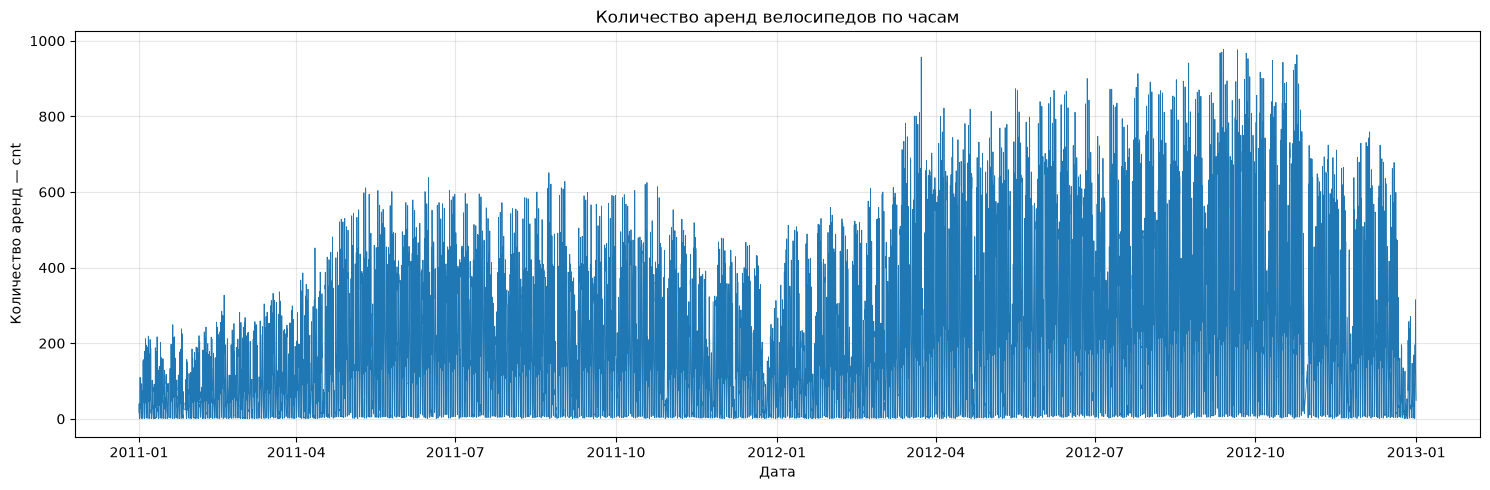

In [4]:
full_index = pd.date_range(
    start=series.index.min(),
    end=series.index.max(),
    freq="h"
)

missing_hours = full_index.difference(series.index)

print("Пропущено часов:", len(missing_hours))

plt.figure(figsize=(15, 5))
plt.plot(series.index, series.values, linewidth=0.6)
plt.title("Количество аренд велосипедов по часам")
plt.xlabel("Дата")
plt.ylabel("Количество аренд — cnt")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [5]:
# Восстанавливаем непрерывную часовую сетку
series = series.asfreq("h")

# True — реальное наблюдение, False — отсутствовавший час
observed_mask = series.notna()

# Заполняем пропуски предыдущим известным значением
series = series.ffill()

print("Всего часов:", len(series))
print("Заполнено пропусков:", (~observed_mask).sum())
print("Осталось пропусков:", series.isna().sum())

Всего часов: 17544
Заполнено пропусков: 165
Осталось пропусков: 0


Обучение: 12280 часов, с 2011-01-01 00:00:00 по 2012-05-26 15:00:00
Валидация: 2632 часов, с 2012-05-26 16:00:00 по 2012-09-13 07:00:00
Тест: 2632 часов, с 2012-09-13 08:00:00 по 2012-12-31 23:00:00


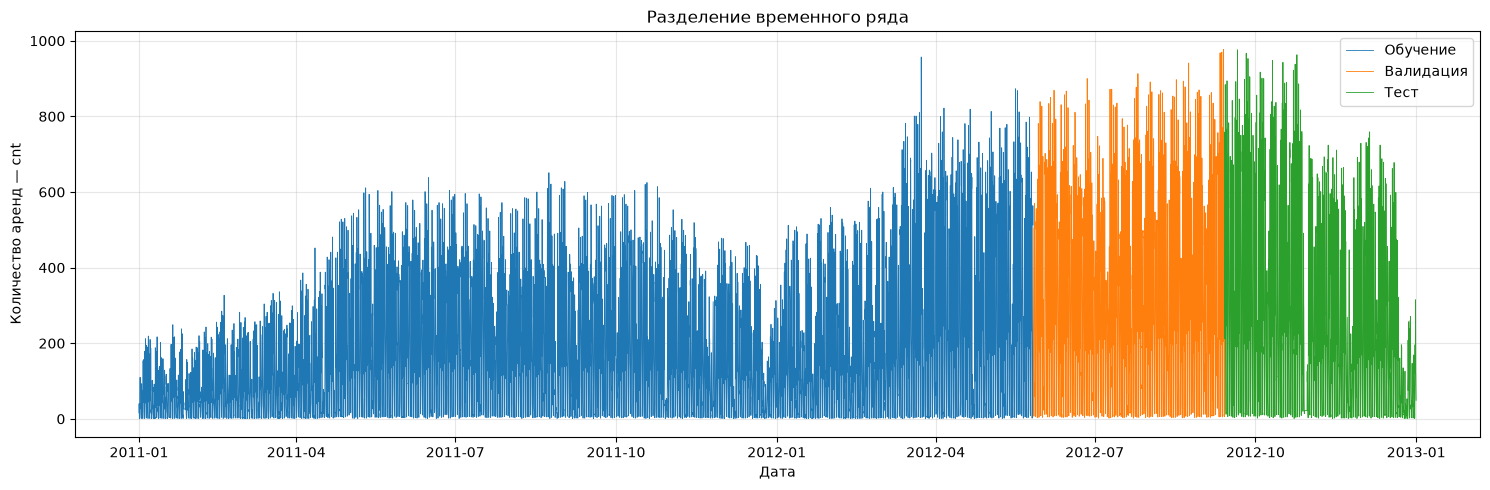

In [6]:
n = len(series)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

train = series.iloc[:train_end]
val = series.iloc[train_end:val_end]
test = series.iloc[val_end:]

# Маски для оценки только по реальным значениям
train_mask = observed_mask.iloc[:train_end]
val_mask = observed_mask.iloc[train_end:val_end]
test_mask = observed_mask.iloc[val_end:]

for name, part in [
    ("Обучение", train),
    ("Валидация", val),
    ("Тест", test)
]:
    print(
        f"{name}: {len(part)} часов, "
        f"с {part.index.min()} по {part.index.max()}"
    )

plt.figure(figsize=(15, 5))

plt.plot(train.index, train, label="Обучение", linewidth=0.6)
plt.plot(val.index, val, label="Валидация", linewidth=0.6)
plt.plot(test.index, test, label="Тест", linewidth=0.6)

plt.title("Разделение временного ряда")
plt.xlabel("Дата")
plt.ylabel("Количество аренд — cnt")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

ARIMA

In [17]:
def make_calendar_features(index):
    features = pd.DataFrame(index=index)

    # Суточный цикл и его более короткие составляющие
    for k in range(1, 4):
        features[f"hour_sin_{k}"] = np.sin(
            2 * np.pi * k * index.hour / 24
        )
        features[f"hour_cos_{k}"] = np.cos(
            2 * np.pi * k * index.hour / 24
        )

    # Понедельник — базовый день, остальные сравниваются с ним
    for day in range(1, 7):
        features[f"weekday_{day}"] = (
            index.dayofweek == day
        ).astype(float)

    features["month_sin"] = np.sin(
        2 * np.pi * (index.month - 1) / 12
    )
    features["month_cos"] = np.cos(
        2 * np.pi * (index.month - 1) / 12
    )

    return features.astype(float)


calendar_features = make_calendar_features(series.index)

calendar_train = calendar_features.iloc[:train_end]
calendar_day = calendar_features.iloc[train_end:train_end + 24]

display(calendar_train.head())

,hour_sin_1,hour_cos_1,hour_sin_2,hour_cos_2,hour_sin_3,hour_cos_3,weekday_1,weekday_2,weekday_3,weekday_4,weekday_5,weekday_6,month_sin,month_cos
datetime,,,,,,,,,,,,,,
2011-01-01 00:00:00,0.000000,1.000000,0.000000,1.000000e+00,0.000000e+00,1.000000e+00,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
2011-01-01 01:00:00,0.258819,0.965926,0.500000,8.660254e-01,7.071068e-01,7.071068e-01,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
2011-01-01 02:00:00,0.500000,0.866025,0.866025,5.000000e-01,1.000000e+00,6.123234e-17,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
2011-01-01 03:00:00,0.707107,0.707107,1.000000,6.123234e-17,7.071068e-01,-7.071068e-01,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
2011-01-01 04:00:00,0.866025,0.500000,0.866025,-5.000000e-01,1.224647e-16,-1.000000e+00,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0


In [14]:
HORIZON = 24

# Первые сутки после конца обучающего периода
actual_day = val.iloc[:HORIZON]
mask_day = val_mask.iloc[:HORIZON]

# Сразу 24 шага вперёд без обновления фактическими данными
arima_day_pred = pd.Series(
    np.maximum(
        np.asarray(arima_result.forecast(steps=HORIZON)),
        0
    ),
    index=actual_day.index
)

print("Последний известный час:", train.index[-1])
print("Начало прогноза:", actual_day.index[0])
print("Конец прогноза:", actual_day.index[-1])

Последний известный час: 2012-05-26 15:00:00
Начало прогноза: 2012-05-26 16:00:00
Конец прогноза: 2012-05-27 15:00:00


In [15]:
naive_day_pred = series.shift(168).loc[actual_day.index]

day_comparison = pd.DataFrame({
    "Факт": actual_day.where(mask_day),
    "ARIMA": arima_day_pred,
    "Неделю назад": naive_day_pred
})

display(day_comparison.round(1))

day_metrics = pd.DataFrame({
    "ARIMA": calculate_metrics(
        actual_day, arima_day_pred, mask_day
    ),
    "Значение неделю назад": calculate_metrics(
        actual_day, naive_day_pred, mask_day
    )
}).T

display(day_metrics.round(3))

,Факт,ARIMA,Неделю назад
datetime,,,
2012-05-26 16:00:00,504.0,424.7,642.0
2012-05-26 17:00:00,462.0,355.1,626.0
2012-05-26 18:00:00,415.0,308.6,645.0
2012-05-26 19:00:00,373.0,278.7,432.0
2012-05-26 20:00:00,255.0,260.9,315.0
2012-05-26 21:00:00,251.0,253.6,259.0
2012-05-26 22:00:00,204.0,251.9,338.0
2012-05-26 23:00:00,150.0,253.3,239.0
2012-05-27 00:00:00,137.0,255.4,170.0


,MAE,RMSE,R²
ARIMA,161.029,185.765,0.109
Значение неделю назад,59.458,82.420,0.825


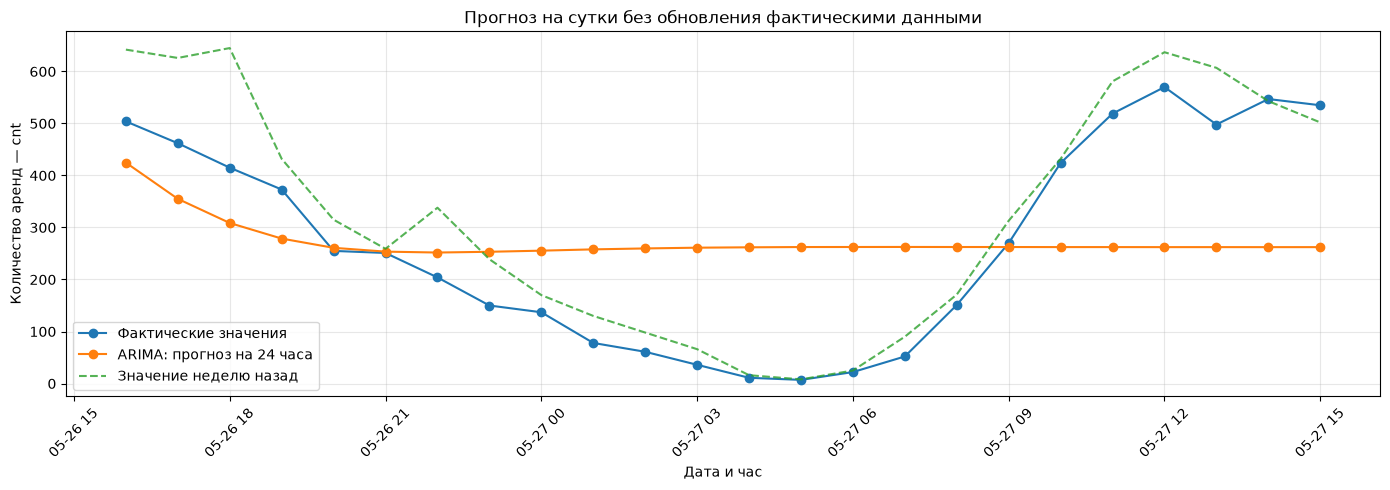

In [16]:
plt.figure(figsize=(14, 5))

plt.plot(
    day_comparison.index,
    day_comparison["Факт"],
    marker="o",
    label="Фактические значения"
)

plt.plot(
    day_comparison.index,
    day_comparison["ARIMA"],
    marker="o",
    label="ARIMA: прогноз на 24 часа"
)

plt.plot(
    day_comparison.index,
    day_comparison["Неделю назад"],
    linestyle="--",
    label="Значение неделю назад",
    alpha=0.8
)

plt.title("Прогноз на сутки без обновления фактическими данными")
plt.xlabel("Дата и час")
plt.ylabel("Количество аренд — cnt")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

CNN

In [19]:
from sklearn.preprocessing import MinMaxScaler
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(42)

WINDOW = 168
HORIZON = 24

scaler = MinMaxScaler()
scaler.fit(train.to_numpy().reshape(-1, 1))

scaled_series = scaler.transform(
    series.to_numpy().reshape(-1, 1)
).astype(np.float32)

In [20]:
def make_daily_windows(start, end, step=1):
    x, y = [], []

    for i in range(max(start, WINDOW), end - HORIZON + 1, step):
        if not observed_mask.iloc[i:i + HORIZON].all():
            continue

        x.append(scaled_series[i - WINDOW:i])
        y.append(scaled_series[i:i + HORIZON, 0])

    return (
        np.asarray(x, dtype=np.float32),
        np.asarray(y, dtype=np.float32)
    )


X_train_24, y_train_24 = make_daily_windows(
    0, train_end
)

X_val_24, y_val_24 = make_daily_windows(
    train_end, val_end, step=24
)

print("Обучение:", X_train_24.shape, y_train_24.shape)
print("Валидация:", X_val_24.shape, y_val_24.shape)

Обучение: (10568, 168, 1) (10568, 24)
Валидация: (109, 168, 1) (109, 24)


In [21]:
cnn_model = keras.Sequential([
    layers.Input(shape=(WINDOW, 1)),

    layers.Conv1D(
        filters=32,
        kernel_size=5,
        activation="relu",
        padding="causal"
    ),
    layers.MaxPooling1D(pool_size=2),

    layers.Conv1D(
        filters=64,
        kernel_size=3,
        activation="relu",
        padding="causal"
    ),
    layers.MaxPooling1D(pool_size=2),

    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.2),

    layers.Dense(HORIZON)
])

cnn_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="mse"
)

cnn_model.summary()

W0000 00:00:1791807686.990764 1219532 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
W0000 00:00:1791807687.067014 1219532 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 168, 32)        │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 84, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 84, 64)         │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 42, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2688)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       172,096 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 24)             │         1,560 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 180,056 (703.34 KB)

 Trainable params: 180,056 (703.34 KB)

 Non-trainable params: 0 (0.00 B)

In [22]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history_cnn = cnn_model.fit(
    X_train_24,
    y_train_24,
    validation_data=(X_val_24, y_val_24),
    epochs=40,
    batch_size=64,
    shuffle=False,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/40
166/166 ━━━━━━━━━━━━━━━━━━━━ 8s 25ms/step - loss: 0.0163 - val_loss: 0.0177
Epoch 2/40
166/166 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0121 - val_loss: 0.0135
Epoch 3/40
166/166 ━━━━━━━━━━━━━━━━━━━━ 0s 978us/step - loss: 0.0106 - val_loss: 0.0119
Epoch 4/40
166/166 ━━━━━━━━━━━━━━━━━━━━ 0s 984us/step - loss: 0.0097 - val_loss: 0.0105
Epoch 5/40
166/166 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0091 - val_loss: 0.0104
Epoch 6/40
166/166 ━━━━━━━━━━━━━━━━━━━━ 0s 992us/step - loss: 0.0089 - val_loss: 0.0100
Epoch 7/40
166/166 ━━━━━━━━━━━━━━━━━━━━ 0s 982us/step - loss: 0.0084 - val_loss: 0.0098
Epoch 8/40
166/166 ━━━━━━━━━━━━━━━━━━━━ 0s 986us/step - loss: 0.0083 - val_loss: 0.0096
Epoch 9/40
166/166 ━━━━━━━━━━━━━━━━━━━━ 0s 984us/step - loss: 0.0080 - val_loss: 0.0102
Epoch 10/40
166/166 ━━━━━━━━━━━━━━━━━━━━ 0s 987us/step - loss: 0.0080 - val_loss: 0.0096
Epoch 11/40
166/166 ━━━━━━━━━━━━━━━━━━━━ 0s 991us/step - loss: 0.0078 - val_loss: 0.0094
Epoch 12/40
166/166 ━━━━━━━━━━━━━━━

In [23]:
input_week = scaled_series[
    train_end - WINDOW:train_end
].reshape(1, WINDOW, 1)

cnn_pred_scaled = cnn_model.predict(
    input_week,
    verbose=0
)

cnn_pred_values = scaler.inverse_transform(
    cnn_pred_scaled.reshape(-1, 1)
).ravel()

actual_day = val.iloc[:HORIZON]
mask_day = val_mask.iloc[:HORIZON]

cnn_day_pred = pd.Series(
    np.maximum(cnn_pred_values, 0),
    index=actual_day.index
)

day_metrics = pd.DataFrame({
    "ARIMA": calculate_metrics(
        actual_day, arima_day_pred, mask_day
    ),
    "CNN": calculate_metrics(
        actual_day, cnn_day_pred, mask_day
    ),
    "Значение неделю назад": calculate_metrics(
        actual_day, naive_day_pred, mask_day
    )
}).T

display(day_metrics.round(3))

,MAE,RMSE,R²
ARIMA,161.029,185.765,0.109
CNN,41.426,55.898,0.919
Значение неделю назад,59.458,82.420,0.825


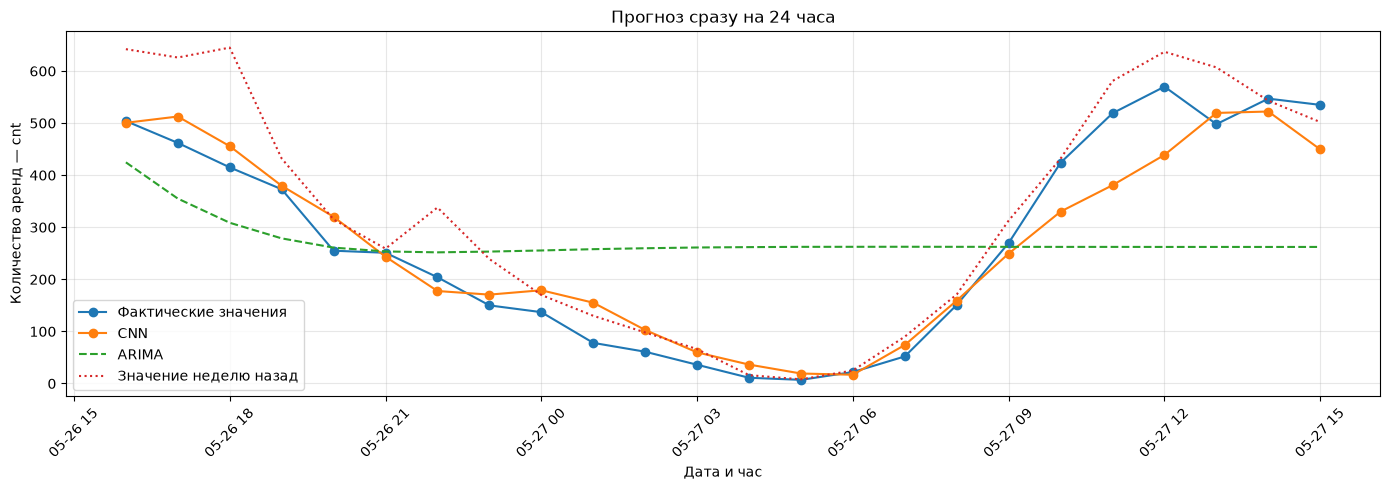

In [24]:
plt.figure(figsize=(14, 5))

plt.plot(
    actual_day.index,
    actual_day.where(mask_day),
    marker="o",
    label="Фактические значения"
)

plt.plot(
    cnn_day_pred.index,
    cnn_day_pred,
    marker="o",
    label="CNN"
)

plt.plot(
    arima_day_pred.index,
    arima_day_pred,
    linestyle="--",
    label="ARIMA"
)

plt.plot(
    naive_day_pred.index,
    naive_day_pred,
    linestyle=":",
    label="Значение неделю назад"
)

plt.title("Прогноз сразу на 24 часа")
plt.xlabel("Дата и час")
plt.ylabel("Количество аренд — cnt")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

LSTM

In [25]:
keras.utils.set_random_seed(42)

lstm_model = keras.Sequential([
    layers.Input(shape=(WINDOW, 1)),

    layers.LSTM(64),

    layers.Dense(64, activation="relu"),
    layers.Dropout(0.2),

    layers.Dense(HORIZON)
])

lstm_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="mse"
)

lstm_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 24)             │         1,560 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,616 (88.34 KB)

 Trainable params: 22,616 (88.34 KB)

 Non-trainable params: 0 (0.00 B)

In [26]:
early_stopping_lstm = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history_lstm = lstm_model.fit(
    X_train_24,
    y_train_24,
    validation_data=(X_val_24, y_val_24),
    epochs=40,
    batch_size=64,
    shuffle=False,
    callbacks=[early_stopping_lstm],
    verbose=1
)

Epoch 1/40
166/166 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - loss: 0.0188 - val_loss: 0.0285
Epoch 2/40
166/166 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0142 - val_loss: 0.0255
Epoch 3/40
166/166 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0142 - val_loss: 0.0242
Epoch 4/40
166/166 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0134 - val_loss: 0.0238
Epoch 5/40
166/166 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0130 - val_loss: 0.0231
Epoch 6/40
166/166 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0126 - val_loss: 0.0222
Epoch 7/40
166/166 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0120 - val_loss: 0.0194
Epoch 8/40
166/166 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0114 - val_loss: 0.0180
Epoch 9/40
166/166 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0109 - val_loss: 0.0174
Epoch 10/40
166/166 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0108 - val_loss: 0.0172
Epoch 11/40
166/166 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0104 - val_loss: 0.0169
Epoch 12/40
166/166 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step

In [27]:
input_week = scaled_series[
    train_end - WINDOW:train_end
].reshape(1, WINDOW, 1)

lstm_pred_scaled = lstm_model.predict(
    input_week,
    verbose=0
)

lstm_pred_values = scaler.inverse_transform(
    lstm_pred_scaled.reshape(-1, 1)
).ravel()

lstm_day_pred = pd.Series(
    np.maximum(lstm_pred_values, 0),
    index=actual_day.index
)

In [28]:
day_metrics = pd.DataFrame({
    "ARIMA": calculate_metrics(
        actual_day, arima_day_pred, mask_day
    ),
    "CNN": calculate_metrics(
        actual_day, cnn_day_pred, mask_day
    ),
    "LSTM": calculate_metrics(
        actual_day, lstm_day_pred, mask_day
    ),
    "Значение неделю назад": calculate_metrics(
        actual_day, naive_day_pred, mask_day
    )
}).T

display(day_metrics.round(3))

,MAE,RMSE,R²
ARIMA,161.029,185.765,0.109
CNN,41.426,55.898,0.919
LSTM,62.583,86.607,0.806
Значение неделю назад,59.458,82.420,0.825


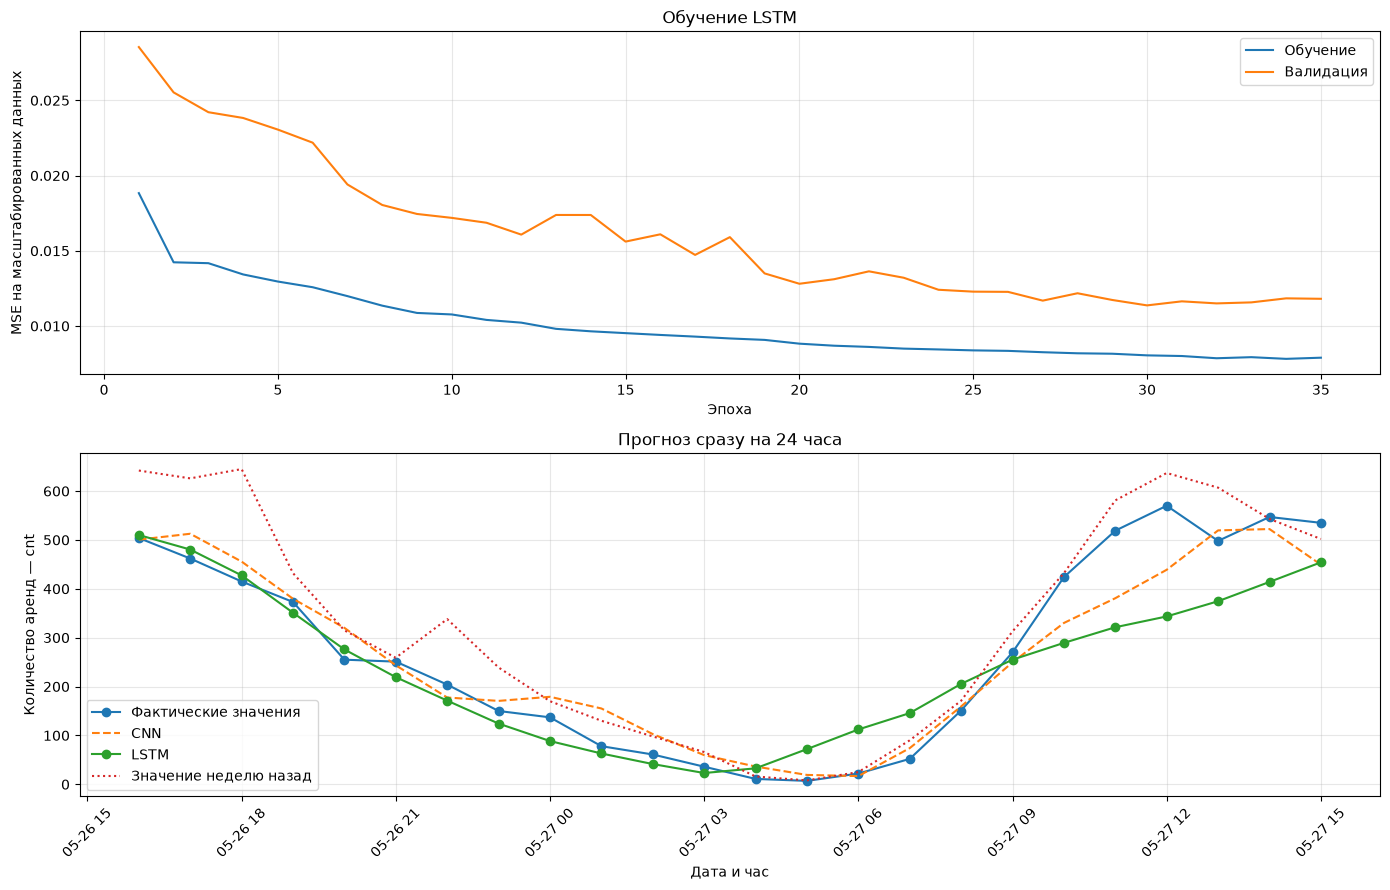

In [29]:
fig, axes = plt.subplots(2, 1, figsize=(14, 9))

epochs = np.arange(1, len(history_lstm.history["loss"]) + 1)

axes[0].plot(
    epochs,
    history_lstm.history["loss"],
    label="Обучение"
)
axes[0].plot(
    epochs,
    history_lstm.history["val_loss"],
    label="Валидация"
)

axes[0].set_title("Обучение LSTM")
axes[0].set_xlabel("Эпоха")
axes[0].set_ylabel("MSE на масштабированных данных")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    actual_day.index,
    actual_day.where(mask_day),
    marker="o",
    label="Фактические значения"
)
axes[1].plot(
    cnn_day_pred.index,
    cnn_day_pred,
    linestyle="--",
    label="CNN"
)
axes[1].plot(
    lstm_day_pred.index,
    lstm_day_pred,
    marker="o",
    label="LSTM"
)
axes[1].plot(
    naive_day_pred.index,
    naive_day_pred,
    linestyle=":",
    label="Значение неделю назад"
)

axes[1].set_title("Прогноз сразу на 24 часа")
axes[1].set_xlabel("Дата и час")
axes[1].set_ylabel("Количество аренд — cnt")
axes[1].tick_params(axis="x", rotation=45)
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

CNN + LSTM

In [30]:
keras.utils.set_random_seed(42)

cnn_lstm_model = keras.Sequential([
    layers.Input(shape=(WINDOW, 1)),

    layers.Conv1D(
        filters=32,
        kernel_size=5,
        activation="relu",
        padding="causal"
    ),
    layers.MaxPooling1D(pool_size=2),

    layers.LSTM(64),

    layers.Dense(64, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(HORIZON)
])

cnn_lstm_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="mse"
)

early_stopping_cnn_lstm = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history_cnn_lstm = cnn_lstm_model.fit(
    X_train_24,
    y_train_24,
    validation_data=(X_val_24, y_val_24),
    epochs=40,
    batch_size=64,
    shuffle=False,
    callbacks=[early_stopping_cnn_lstm],
    verbose=1
)

Epoch 1/40
166/166 ━━━━━━━━━━━━━━━━━━━━ 12s 4ms/step - loss: 0.0209 - val_loss: 0.0292
Epoch 2/40
166/166 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0138 - val_loss: 0.0223
Epoch 3/40
166/166 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0132 - val_loss: 0.0211
Epoch 4/40
166/166 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0124 - val_loss: 0.0201
Epoch 5/40
166/166 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0116 - val_loss: 0.0187
Epoch 6/40
166/166 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0112 - val_loss: 0.0183
Epoch 7/40
166/166 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0106 - val_loss: 0.0172
Epoch 8/40
166/166 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0103 - val_loss: 0.0169
Epoch 9/40
166/166 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0099 - val_loss: 0.0166
Epoch 10/40
166/166 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0096 - val_loss: 0.0162
Epoch 11/40
166/166 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0095 - val_loss: 0.0158
Epoch 12/40
166/166 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/ste

In [31]:
input_week = scaled_series[
    train_end - WINDOW:train_end
].reshape(1, WINDOW, 1)

pred_scaled = cnn_lstm_model.predict(input_week, verbose=0)

pred_values = scaler.inverse_transform(
    pred_scaled.reshape(-1, 1)
).ravel()

cnn_lstm_day_pred = pd.Series(
    np.maximum(pred_values, 0),
    index=actual_day.index
)

predictions = {
    "ARIMA": arima_day_pred,
    "CNN": cnn_day_pred,
    "LSTM": lstm_day_pred,
    "CNN–LSTM": cnn_lstm_day_pred,
    "Значение неделю назад": naive_day_pred
}

day_metrics = pd.DataFrame({
    name: calculate_metrics(actual_day, pred, mask_day)
    for name, pred in predictions.items()
}).T

display(day_metrics.round(3))

,MAE,RMSE,R²
ARIMA,161.029,185.765,0.109
CNN,41.426,55.898,0.919
LSTM,62.583,86.607,0.806
CNN–LSTM,43.728,62.011,0.901
Значение неделю назад,59.458,82.420,0.825


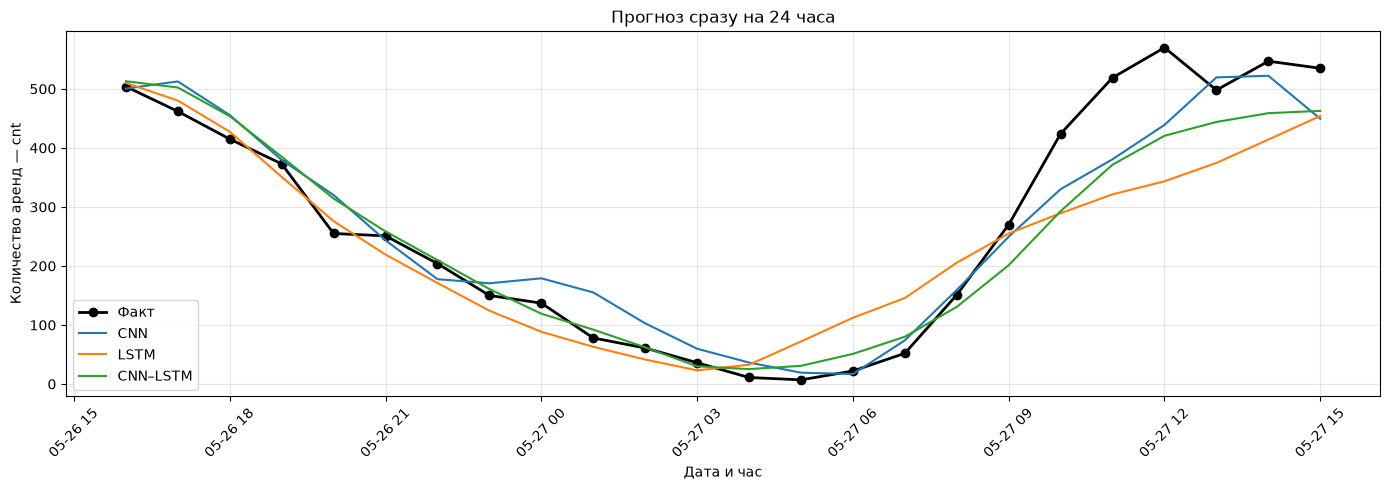

In [32]:
plt.figure(figsize=(14, 5))

plt.plot(
    actual_day.index,
    actual_day.where(mask_day),
    color="black",
    marker="o",
    linewidth=2,
    label="Факт"
)

for name in ["CNN", "LSTM", "CNN–LSTM"]:
    pred = predictions[name]
    plt.plot(pred.index, pred, label=name)

plt.title("Прогноз сразу на 24 часа")
plt.xlabel("Дата и час")
plt.ylabel("Количество аренд — cnt")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Test

In [33]:
test_starts = np.arange(
    val_end,
    len(series) - HORIZON + 1,
    HORIZON
)

X_test_24 = np.asarray([
    scaled_series[i - WINDOW:i]
    for i in test_starts
], dtype=np.float32)

actual_test_24 = np.asarray([
    series.iloc[i:i + HORIZON].to_numpy()
    for i in test_starts
])

mask_test_24 = np.asarray([
    observed_mask.iloc[i:i + HORIZON].to_numpy()
    for i in test_starts
], dtype=bool)

print("Суточных прогнозов:", len(test_starts))
print("Часов с реальными значениями:", mask_test_24.sum())

Суточных прогнозов: 109
Часов с реальными значениями: 2576


In [34]:
test_predictions = {}

for name, model in {
    "CNN": cnn_model,
    "LSTM": lstm_model,
    "CNN–LSTM": cnn_lstm_model
}.items():

    pred_scaled = model.predict(X_test_24, verbose=0)

    pred = scaler.inverse_transform(
        pred_scaled.reshape(-1, 1)
    ).reshape(-1, HORIZON)

    test_predictions[name] = np.maximum(pred, 0)

In [35]:
# К началу теста валидационный период уже известен
arima_state = arima_result.extend(
    val.where(val_mask).to_numpy()
)

arima_test_predictions = []

for number, i in enumerate(test_starts, start=1):
    # Прогнозируем все 24 часа без обновления внутри суток
    pred = np.asarray(
        arima_state.forecast(steps=HORIZON)
    )
    arima_test_predictions.append(np.maximum(pred, 0))

    # Только после прогноза добавляем прошедшие сутки
    observed_day = series.iloc[i:i + HORIZON].where(
        observed_mask.iloc[i:i + HORIZON]
    )

    arima_state = arima_state.extend(
        observed_day.to_numpy()
    )

    if number % 20 == 0:
        print(f"Обработано {number} из {len(test_starts)} суток")

test_predictions["ARIMA"] = np.asarray(
    arima_test_predictions
)

Обработано 20 из 109 суток
Обработано 40 из 109 суток
Обработано 60 из 109 суток
Обработано 80 из 109 суток
Обработано 100 из 109 суток


In [36]:
test_predictions["Значение неделю назад"] = np.asarray([
    series.iloc[i - 168:i - 168 + HORIZON].to_numpy()
    for i in test_starts
])

test_results = {}

y_true = actual_test_24[mask_test_24]

for name, pred in test_predictions.items():
    y_pred = pred[mask_test_24]

    test_results[name] = {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R²": r2_score(y_true, y_pred)
    }

test_metrics = pd.DataFrame(test_results).T.sort_values("MAE")

display(test_metrics.round(3))

,MAE,RMSE,R²
CNN–LSTM,67.315,97.491,0.794
Значение неделю назад,69.044,118.701,0.695
LSTM,70.199,100.056,0.783
CNN,76.765,109.857,0.738
ARIMA,166.202,201.750,0.118


CNN + LSTM с лагами

In [41]:
LAGS = [1, 24, 48, 72, 168]

features_more = pd.DataFrame({"cnt": series})

for lag in LAGS:
    features_more[f"lag_{lag}"] = series.shift(lag)

scaled_more = np.column_stack([
    scaler.transform(
        features_more[[column]].to_numpy()
    ).ravel()
    for column in features_more.columns
]).astype(np.float32)


def make_more_lag_windows(start, end, step=1):
    x, y, starts = [], [], []

    first_start = max(start, WINDOW + max(LAGS))

    for i in range(first_start, end - HORIZON + 1, step):
        if not observed_mask.iloc[i:i + HORIZON].all():
            continue

        x.append(scaled_more[i - WINDOW:i])
        y.append(scaled_series[i:i + HORIZON, 0])
        starts.append(i)

    return (
        np.asarray(x, dtype=np.float32),
        np.asarray(y, dtype=np.float32),
        np.asarray(starts)
    )


X_train_more, y_train_more, _ = make_more_lag_windows(
    0, train_end
)

X_val_more, y_val_more, more_val_starts = make_more_lag_windows(
    train_end, val_end, step=24
)

# Проверяем совпадение примеров с вариантом из двух лагов
assert np.array_equal(more_val_starts, multi_val_starts)
assert np.array_equal(y_train_more, y_train_multi)
assert np.array_equal(y_val_more, y_val_multi)

print("Обучение:", X_train_more.shape)
print("Валидация:", X_val_more.shape)

Обучение: (10473, 168, 6)
Валидация: (109, 168, 6)


In [42]:
keras.utils.set_random_seed(42)

cnn_lstm_more_model = keras.Sequential([
    layers.Input(shape=(WINDOW, len(LAGS) + 1)),

    layers.Conv1D(
        filters=32,
        kernel_size=5,
        activation="relu",
        padding="causal"
    ),
    layers.MaxPooling1D(pool_size=2),

    layers.LSTM(64),

    layers.Dense(64, activation="relu"),
    layers.Dropout(0.2),

    layers.Dense(HORIZON)
])

cnn_lstm_more_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="mse"
)

history_more = cnn_lstm_more_model.fit(
    X_train_more,
    y_train_more,
    validation_data=(X_val_more, y_val_more),
    epochs=40,
    batch_size=64,
    shuffle=False,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=5,
            restore_best_weights=True
        )
    ],
    verbose=1
)

Epoch 1/40
164/164 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0205 - val_loss: 0.0316
Epoch 2/40
164/164 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0138 - val_loss: 0.0219
Epoch 3/40
164/164 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0123 - val_loss: 0.0198
Epoch 4/40
164/164 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0116 - val_loss: 0.0180
Epoch 5/40
164/164 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0109 - val_loss: 0.0171
Epoch 6/40
164/164 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0105 - val_loss: 0.0163
Epoch 7/40
164/164 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0099 - val_loss: 0.0155
Epoch 8/40
164/164 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0094 - val_loss: 0.0151
Epoch 9/40
164/164 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0089 - val_loss: 0.0141
Epoch 10/40
164/164 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0086 - val_loss: 0.0139
Epoch 11/40
164/164 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0083 - val_loss: 0.0132
Epoch 12/40
164/164 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step

In [43]:
more_val_pred = restore_predictions(
    cnn_lstm_more_model.predict(X_val_more, verbose=0)
)

predictions_compare = {
    "CNN–LSTM без явных лагов": old_val_pred,
    "CNN–LSTM: 2 лага": multi_val_pred,
    "CNN–LSTM: 5 лагов": more_val_pred,
    "Значение неделю назад": weekly_multi_val
}

results_compare = {}
actual_flat = actual_multi_val.ravel()

for name, pred in predictions_compare.items():
    pred_flat = pred.ravel()

    results_compare[name] = {
        "MAE": mean_absolute_error(actual_flat, pred_flat),
        "RMSE": np.sqrt(
            mean_squared_error(actual_flat, pred_flat)
        ),
        "R²": r2_score(actual_flat, pred_flat)
    }

display(pd.DataFrame(results_compare).T.round(3))

,MAE,RMSE,R²
CNN–LSTM без явных лагов,67.694,98.469,0.805
CNN–LSTM: 2 лага,65.013,94.244,0.821
CNN–LSTM: 5 лагов,59.318,87.875,0.845
Значение неделю назад,57.800,98.107,0.806


In [40]:
def restore_predictions(values):
    return np.maximum(
        scaler.inverse_transform(
            np.asarray(values).reshape(-1, 1)
        ).reshape(-1, HORIZON),
        0
    )


old_val_pred = restore_predictions(
    cnn_lstm_model.predict(
        X_val_multi[:, :, :1],
        verbose=0
    )
)

multi_val_pred = restore_predictions(
    cnn_lstm_multi_model.predict(
        X_val_multi,
        verbose=0
    )
)

actual_multi_val = np.asarray([
    series.iloc[i:i + HORIZON].to_numpy()
    for i in multi_val_starts
])

weekly_multi_val = np.asarray([
    series.iloc[i - 168:i - 168 + HORIZON].to_numpy()
    for i in multi_val_starts
])

results_multi = {}

for name, pred in {
    "CNN–LSTM": old_val_pred,
    "CNN–LSTM с лагами на входе": multi_val_pred,
    "Значение неделю назад": weekly_multi_val
}.items():
    actual_flat = actual_multi_val.ravel()
    pred_flat = pred.ravel()

    results_multi[name] = {
        "MAE": mean_absolute_error(actual_flat, pred_flat),
        "RMSE": np.sqrt(
            mean_squared_error(actual_flat, pred_flat)
        ),
        "R²": r2_score(actual_flat, pred_flat)
    }

display(pd.DataFrame(results_multi).T.round(3))

,MAE,RMSE,R²
CNN–LSTM,67.694,98.469,0.805
CNN–LSTM с лагами на входе,65.013,94.244,0.821
Значение неделю назад,57.800,98.107,0.806


In [44]:
X_test_more = np.asarray([
    scaled_more[i - WINDOW:i]
    for i in test_starts
], dtype=np.float32)

assert np.isfinite(X_test_more).all()

print("Форма входа:", X_test_more.shape)
print("Количество суточных прогнозов:", len(X_test_more))

Форма входа: (109, 168, 6)
Количество суточных прогнозов: 109


In [45]:
more_test_scaled = cnn_lstm_more_model.predict(
    X_test_more,
    verbose=0
)

more_test_pred = restore_predictions(more_test_scaled)

test_predictions["CNN–LSTM: 5 лагов"] = more_test_pred

In [46]:
test_results = {}

y_true = actual_test_24[mask_test_24]

for name, pred in test_predictions.items():
    y_pred = pred[mask_test_24]

    test_results[name] = {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(
            mean_squared_error(y_true, y_pred)
        ),
        "R²": r2_score(y_true, y_pred)
    }

test_metrics = pd.DataFrame(test_results).T.sort_values("MAE")

display(test_metrics.round(3))

,MAE,RMSE,R²
CNN–LSTM: 5 лагов,60.747,89.671,0.826
CNN–LSTM,67.315,97.491,0.794
Значение неделю назад,69.044,118.701,0.695
LSTM,70.199,100.056,0.783
CNN,76.765,109.857,0.738
ARIMA,166.202,201.750,0.118


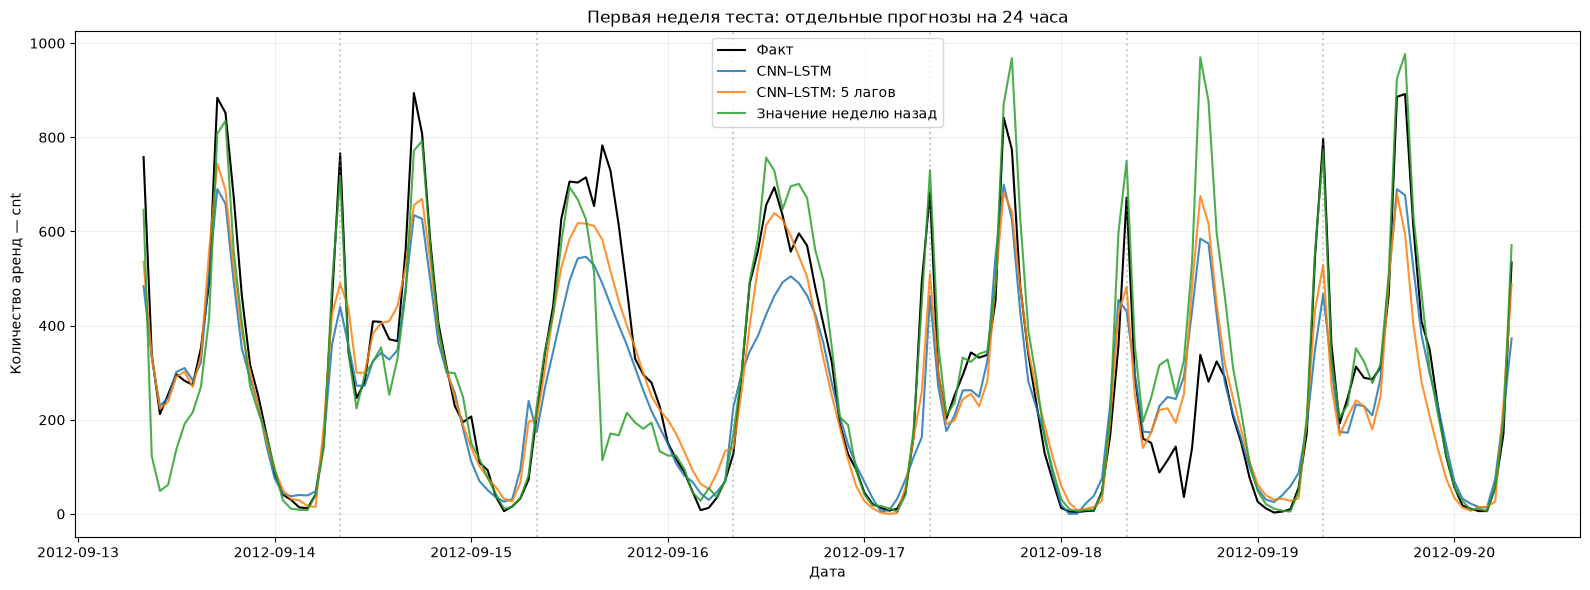

In [47]:
days_to_plot = min(7, len(test_starts))

plot_dates = pd.DatetimeIndex([
    date
    for i in test_starts[:days_to_plot]
    for date in series.index[i:i + HORIZON]
])

plot_actual = actual_test_24[:days_to_plot].copy()
plot_actual[~mask_test_24[:days_to_plot]] = np.nan

plt.figure(figsize=(16, 6))

plt.plot(
    plot_dates,
    plot_actual.ravel(),
    color="black",
    linewidth=1.5,
    label="Факт"
)

for name in [
    "CNN–LSTM",
    "CNN–LSTM: 5 лагов",
    "Значение неделю назад"
]:
    plt.plot(
        plot_dates,
        test_predictions[name][:days_to_plot].ravel(),
        label=name,
        alpha=0.85
    )

for i in test_starts[1:days_to_plot]:
    plt.axvline(
        series.index[i],
        color="gray",
        linestyle=":",
        alpha=0.4
    )

plt.title("Первая неделя теста: отдельные прогнозы на 24 часа")
plt.xlabel("Дата")
plt.ylabel("Количество аренд — cnt")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()